# Notebook 02: primeira análise

**Projeto de Análise de Dados e BI** · Tema: redução de faltas em consultas (no-show) em clínicas

**Equipe:** Cauê Franco, Lucio Lima e Daniel Vieira

## Objetivo deste notebook

Esta é a **primeira versão da análise**, feita para validar os passos antes do dashboard e da apresentação. Ela
responde à pergunta central do projeto: **quem tem mais chance de faltar e o que a clínica pode fazer para reduzir
isso?**

- **De onde vêm os dados:** só do arquivo `dados/tratados/consultas_tratadas.csv`, gerado pelo notebook
  `01_limpeza`. Este notebook **nunca lê o arquivo original** e **não altera** a base tratada.
- **Fonte original:** *Medical Appointment No Shows*, do Kaggle (autor Joni Hoppen, licença CC BY-NC-SA 4.0).

## Definições (as mesmas do projeto inteiro)

- **Taxa de falta** = consultas com `faltou = 1` ÷ total de consultas, em %.
- **Espera** (`dias_espera`) = dias de calendário entre o agendamento e a consulta.
- **Faixas de idade e de espera:** as da base tratada, com os mesmos rótulos (`0-12`, `13-17`, `18-29`, `30-44`,
  `45-59`, `60+` e `Mesmo dia`, `1-7 dias`, `8-15 dias`, `16-30 dias`, `31+ dias`).

## As 8 seções

1. Qual é a taxa de falta geral?
2. O tempo de espera pesa na falta?
3. O SMS reduz a falta? (o caso da correlação espúria)
4. Quem falta mais por idade?
5. Algum dia da semana falha mais?
6. Quais bairros têm mais falta?
7. Como as variáveis numéricas se correlacionam com a falta?
8. Achados e próximos passos

Em cada seção: a **pergunta**, o código, o gráfico e uma **leitura** com os números que o próprio notebook calculou.

## Preparação: bibliotecas, cores e carga da base tratada

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

CAMINHO_TRATADO = "../dados/tratados/consultas_tratadas.csv"

# Cores e estilo dos gráficos: uma cor principal, texto em tons de cinza, grade discreta
SUPERFICIE = "#fcfcfb"
TEXTO = "#0b0b0b"
TEXTO_2 = "#52514e"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
AZUL = "#2a78d6"      # cor principal (e "sem SMS")
LARANJA = "#eb6834"   # segunda cor, só quando há dois grupos ("com SMS")
VERMELHO = "#e34948"
NEUTRO = "#f0efec"

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EIXO, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlepad": 12,
    "axes.labelsize": 10, "font.size": 10, "figure.dpi": 100, "legend.frameon": False,
})

# Ordem das categorias (o CSV não guarda ordem): os rótulos são exatamente os do contrato da base tratada
ORDEM_DIA_SEMANA = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado"]
ORDEM_FAIXA_ETARIA = ["0-12", "13-17", "18-29", "30-44", "45-59", "60+"]
ORDEM_FAIXA_ESPERA = ["Mesmo dia", "1-7 dias", "8-15 dias", "16-30 dias", "31+ dias"]

COLUNAS_ESPERADAS = [
    "paciente_id", "consulta_id", "sexo", "data_agendamento", "data_consulta", "idade", "bairro",
    "bolsa_familia", "hipertensao", "diabetes", "alcoolismo", "recebeu_sms", "deficiencia", "faltou",
    "dias_espera", "dia_semana", "faixa_etaria", "faixa_espera", "tem_deficiencia",
]

In [2]:
# paciente_id é só um identificador: lido como texto
df = pd.read_csv(
    CAMINHO_TRATADO,
    dtype={"paciente_id": str},
    parse_dates=["data_agendamento", "data_consulta"],
)

# O CSV não guarda a ordem das categorias; aqui ela é redefinida com os rótulos exatos do contrato
df["dia_semana"] = pd.Categorical(df["dia_semana"], categories=ORDEM_DIA_SEMANA, ordered=True)
df["faixa_etaria"] = pd.Categorical(df["faixa_etaria"], categories=ORDEM_FAIXA_ETARIA, ordered=True)
df["faixa_espera"] = pd.Categorical(df["faixa_espera"], categories=ORDEM_FAIXA_ESPERA, ordered=True)

# Conferência da carga: se algum rótulo não bater com o contrato, a categoria vira nula e o assert para o notebook
assert len(df) == 110_521, f"linhas inesperadas: {len(df)}"
assert list(df.columns) == COLUNAS_ESPERADAS, "as colunas não batem com o contrato da base tratada"
for coluna in ["dia_semana", "faixa_etaria", "faixa_espera"]:
    assert df[coluna].notna().all(), f"rótulo fora do contrato em {coluna}"

print(f"Base tratada carregada: {len(df):,} linhas e {df.shape[1]} colunas.".replace(",", "."))
df.head()

Base tratada carregada: 110.521 linhas e 19 colunas.


,paciente_id,consulta_id,sexo,data_agendamento,data_consulta,idade,bairro,bolsa_familia,hipertensao,diabetes,alcoolismo,recebeu_sms,deficiencia,faltou,dias_espera,dia_semana,faixa_etaria,faixa_espera,tem_deficiencia
0,29872499824296,5642903,F,2016-04-29,2016-04-29,62,JARDIM DA PENHA,0,1,0,0,0,0,0,0,Sexta,60+,Mesmo dia,0
1,558997776694438,5642503,M,2016-04-29,2016-04-29,56,JARDIM DA PENHA,0,0,0,0,0,0,0,0,Sexta,45-59,Mesmo dia,0
2,4262962299951,5642549,F,2016-04-29,2016-04-29,62,MATA DA PRAIA,0,0,0,0,0,0,0,0,Sexta,60+,Mesmo dia,0
3,867951213174,5642828,F,2016-04-29,2016-04-29,8,PONTAL DE CAMBURI,0,0,0,0,0,0,0,0,Sexta,0-12,Mesmo dia,0
4,8841186448183,5642494,F,2016-04-29,2016-04-29,56,JARDIM DA PENHA,0,1,1,0,0,0,0,0,Sexta,45-59,Mesmo dia,0


## Funções de apoio

Três pedaços de código usados em várias seções, para as taxas serem calculadas **sempre do mesmo jeito**:

- `taxa_por(df, coluna)`: tabela com `consultas`, `faltas` e `taxa_pct` (a taxa de falta em %) para cada categoria
  da coluna, na ordem da categoria;
- `grafico_taxa(...)`: gráfico de barras da taxa, com a linha tracejada da taxa geral e o valor em cada barra;
- `fmt_num`, `fmt_pct`, `fmt_r`: formatação em português (vírgula decimal e ponto de milhar).

In [3]:
TAXA_GERAL = df["faltou"].mean() * 100  # taxa de falta geral, em %


def fmt_num(x):
    # 110521 -> "110.521"
    return f"{x:,.0f}".replace(",", ".")


def fmt_pct(x, casas=1):
    # 20.19 -> "20,2%"
    return f"{x:.{casas}f}".replace(".", ",") + "%"


def fmt_r(x):
    # 0.186 -> "0,19"
    x = round(x, 2) + 0.0  # evita "-0,00"
    return f"{x:.2f}".replace(".", ",")


def taxa_por(df, coluna):
    # Uma linha por categoria de `coluna`: consultas, faltas e taxa de falta (faltas / consultas, em %)
    g = df.groupby(coluna, observed=False)["faltou"].agg(consultas="size", faltas="sum")
    g["taxa_pct"] = g["faltas"] / g["consultas"] * 100
    return g.reset_index()


def taxa_de(tabela, coluna, rotulo):
    # Taxa (em %) de uma categoria específica de uma tabela criada por taxa_por
    return tabela.loc[tabela[coluna].astype(str) == rotulo, "taxa_pct"].iloc[0]


def imprimir_taxas(tabela, coluna):
    for _, linha in tabela.iterrows():
        print(f"{str(linha[coluna]):<14}{fmt_num(linha['consultas']):>9} consultas"
              f"{fmt_num(linha['faltas']):>9} faltas{fmt_pct(linha['taxa_pct']):>9}")


def grafico_taxa(tabela, coluna, titulo, ax=None, horizontal=False, mostrar_n=False, xlabel=None, cor=AZUL):
    # Barras da taxa de falta (%) por categoria, com a linha tracejada da taxa geral e o valor em cada barra
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4.5))
    rotulos = tabela[coluna].astype(str).tolist()
    if mostrar_n:
        separador = " " if horizontal else "\n"
        rotulos = [f"{r}{separador}(n = {fmt_num(n)})" for r, n in zip(rotulos, tabela["consultas"])]
    valores = tabela["taxa_pct"].to_numpy()
    teto = max(valores.max(), TAXA_GERAL) * 1.25
    posicoes = np.arange(len(valores))
    if horizontal:
        ax.barh(posicoes, valores, height=0.6, color=cor)
        ax.set_yticks(posicoes, rotulos)
        ax.invert_yaxis()
        ax.axvline(TAXA_GERAL, color=TEXTO_2, linestyle="--", linewidth=1.2)
        ax.set_xlim(0, teto)
        for p, v in zip(posicoes, valores):
            ax.text(v + teto * 0.01, p, fmt_pct(v), va="center", ha="left", color=TEXTO)
        ax.set_xlabel("Taxa de falta (%)")
        ax.xaxis.grid(True, color=GRADE, linewidth=0.8)
        if xlabel:
            ax.set_ylabel(xlabel)
    else:
        ax.bar(posicoes, valores, width=0.55 if len(valores) > 2 else 0.3, color=cor)
        ax.set_xticks(posicoes, rotulos)
        ax.axhline(TAXA_GERAL, color=TEXTO_2, linestyle="--", linewidth=1.2)
        ax.set_ylim(0, teto)
        for p, v in zip(posicoes, valores):
            ax.text(p, v + teto * 0.012, fmt_pct(v), ha="center", va="bottom", color=TEXTO,
                    bbox={"facecolor": SUPERFICIE, "edgecolor": "none", "pad": 1.5})
        ax.set_ylabel("Taxa de falta (%)")
        ax.yaxis.grid(True, color=GRADE, linewidth=0.8)
        if xlabel:
            ax.set_xlabel(xlabel)
    ax.set_axisbelow(True)
    linha_geral = Line2D([0], [0], color=TEXTO_2, linestyle="--", linewidth=1.2,
                         label=f"Taxa geral: {fmt_pct(TAXA_GERAL)}")
    ax.legend(handles=[linha_geral], loc="lower right" if horizontal else "upper right")
    ax.set_title(titulo, loc="left")
    return ax


# Testes das funções de apoio
por_sexo = taxa_por(df, "sexo")
assert list(por_sexo.columns) == ["sexo", "consultas", "faltas", "taxa_pct"]
assert por_sexo["consultas"].sum() == len(df)
assert por_sexo["faltas"].sum() == df["faltou"].sum()
assert 19 <= TAXA_GERAL <= 21, f"taxa geral fora do esperado: {TAXA_GERAL}"
print("OK: taxa_por fecha com o total de consultas e de faltas, e a taxa geral está entre 19% e 21%.")

OK: taxa_por fecha com o total de consultas e de faltas, e a taxa geral está entre 19% e 21%.


## Seção 1: Qual é a taxa de falta geral?

É o número de referência de todo o projeto: de cada 100 consultas agendadas, quantas terminam em falta. Ele foi
recalculado aqui, depois da limpeza, e é a **linha tracejada** que aparece em todos os gráficos seguintes.

In [4]:
total_consultas = len(df)
total_faltas = int(df["faltou"].sum())
total_compareceu = total_consultas - total_faltas

print(f"Consultas:     {fmt_num(total_consultas)}")
print(f"Faltas:        {fmt_num(total_faltas)}")
print(f"Compareceram:  {fmt_num(total_compareceu)}  ({fmt_pct(total_compareceu / total_consultas * 100)})")
print(f"Taxa de falta: {fmt_pct(TAXA_GERAL)}")

assert total_faltas == df["faltou"].eq(1).sum()
assert round(TAXA_GERAL, 1) == round(total_faltas / total_consultas * 100, 1)

Consultas:     110.521
Faltas:        22.314
Compareceram:  88.207  (79,8%)
Taxa de falta: 20,2%


**Leitura.** A base tratada tem **110.521 consultas**, e **22.314** delas terminaram em falta: uma taxa de
**20,2%**, ou seja, cerca de 1 em cada 5 agendados não aparece (os outros 79,8% compareceram). Esse é o número que
usamos como referência nos próximos gráficos. Repare que ele é bem menor que os "30%" do subtítulo do Kaggle: o
número real, medido nos dados, é este.

## Seção 2: O tempo de espera pesa na falta?

**Pergunta:** quanto mais tempo passa entre marcar e ir à consulta, mais o paciente falta? Calculamos a taxa de
falta em cada faixa de espera (`dias_espera`, em dias de calendário).

Mesmo dia        38.562 consultas    1.792 faltas     4,6%
1-7 dias         32.185 consultas    7.772 faltas    24,1%
8-15 dias        13.528 consultas    4.166 faltas    30,8%
16-30 dias       15.868 consultas    5.159 faltas    32,5%
31+ dias         10.378 consultas    3.425 faltas    33,0%

Mesmo dia:           38.562 consultas, 1.792 faltas, 4,6%
Com antecedência:    71.959 consultas, 20.522 faltas, 28,5%
Razão (antecedência / mesmo dia): 6,1


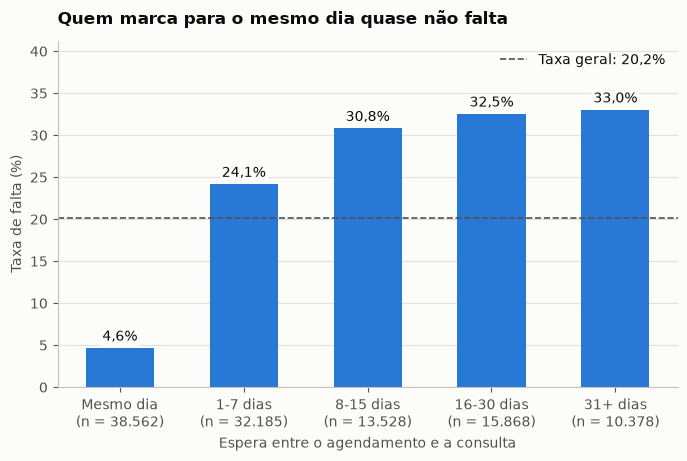

In [5]:
tab_espera = taxa_por(df, "faixa_espera")
imprimir_taxas(tab_espera, "faixa_espera")

assert tab_espera["consultas"].sum() == len(df)
assert list(tab_espera["faixa_espera"]) == ORDEM_FAIXA_ESPERA

# Resumo: mesmo dia contra com antecedência
mesmo_dia = df["faixa_espera"] == "Mesmo dia"
taxa_mesmo_dia = df.loc[mesmo_dia, "faltou"].mean() * 100
taxa_antecedencia = df.loc[~mesmo_dia, "faltou"].mean() * 100
print()
print(f"Mesmo dia:           {fmt_num(mesmo_dia.sum())} consultas, {fmt_num(df.loc[mesmo_dia, 'faltou'].sum())} faltas, {fmt_pct(taxa_mesmo_dia)}")
print(f"Com antecedência:    {fmt_num((~mesmo_dia).sum())} consultas, {fmt_num(df.loc[~mesmo_dia, 'faltou'].sum())} faltas, {fmt_pct(taxa_antecedencia)}")
print(f"Razão (antecedência / mesmo dia): {taxa_antecedencia / taxa_mesmo_dia:.1f}".replace(".", ","))

grafico_taxa(tab_espera, "faixa_espera", "Quem marca para o mesmo dia quase não falta",
             mostrar_n=True, xlabel="Espera entre o agendamento e a consulta")
plt.show()

**Leitura.** O tempo de espera é o fator mais associado à falta nos dados: separa bem quem falta de quem comparece. Quem marca para o **mesmo dia** falta
em **4,6%** das consultas (1.792 de 38.562); quem marca **com antecedência** falta em **28,5%** (20.522 de 71.959),
cerca de **6,1 vezes** mais. Entre as consultas com antecedência, a taxa sobe de 24,1% (1 a 7 dias) para 30,8%
(8 a 15 dias) e chega a 32,5% e 33,0% nas duas faixas mais longas, quando praticamente para de crescer. Uma hipótese
(que os dados não provam) é que quem marca para o mesmo dia está com a necessidade em mãos, e quem marca para semanas
depois tem mais tempo de esquecer ou desistir.

## Seção 3: O SMS reduz a falta? (o caso da correlação espúria)

**Pergunta:** a clínica manda SMS de lembrete. Quem recebe SMS falta menos? Esta seção é o ponto de atenção da
análise: uma **correlação espúria** é quando duas coisas andam juntas nos números, mas a relação aparente vem de um
terceiro fator escondido. A rubrica da disciplina cita esse erro de propósito. Vamos em dois passos: primeiro a
comparação crua, depois a mesma comparação **dentro de cada faixa de espera**.

### Passo 1: a comparação crua

Sem SMS          75.039 consultas   12.530 faltas    16,7%
Com SMS          35.482 consultas    9.784 faltas    27,6%

Diferença (com SMS menos sem SMS): 10,9 pontos percentuais


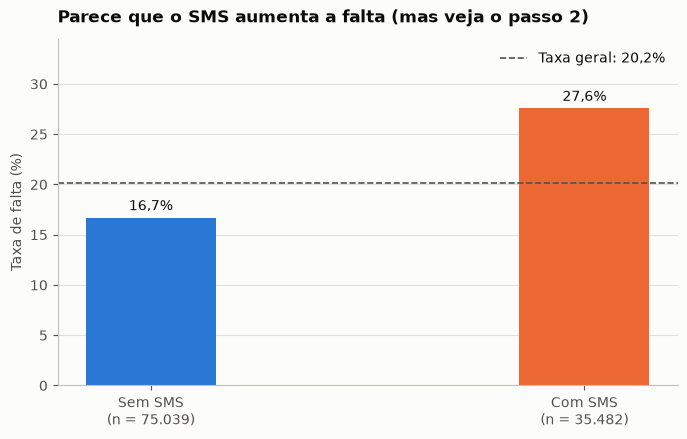

In [6]:
def com_rotulo_sms(dados):
    # Troca 0/1 por texto, com ordem fixa (sem SMS primeiro)
    rotulo = dados["recebeu_sms"].map({0: "Sem SMS", 1: "Com SMS"})
    return dados.assign(sms=pd.Categorical(rotulo, categories=["Sem SMS", "Com SMS"], ordered=True))


sms_cru = taxa_por(com_rotulo_sms(df), "sms")
imprimir_taxas(sms_cru, "sms")

taxa_sem_sms = taxa_de(sms_cru, "sms", "Sem SMS")
taxa_com_sms = taxa_de(sms_cru, "sms", "Com SMS")
print()
print(f"Diferença (com SMS menos sem SMS): {taxa_com_sms - taxa_sem_sms:.1f} pontos percentuais".replace(".", ","))

grafico_taxa(sms_cru, "sms", "Parece que o SMS aumenta a falta (mas veja o passo 2)", mostrar_n=True,
             cor=[AZUL, LARANJA])
plt.show()

**Leitura do passo 1.** À primeira vista, **parece que o SMS aumenta a falta**: quem recebeu SMS faltou em **27,6%**
das consultas (9.784 de 35.482) e quem não recebeu faltou em **16,7%** (12.530 de 75.039), uma diferença de
**10,9 pontos percentuais**. Se parássemos aqui, a conclusão seria "o SMS piora o problema", e essa conclusão seria
um erro. Falta descobrir **quem** recebe o SMS.

### Passo 2: o controle pela espera

Primeiro, quantas consultas de cada faixa de espera receberam SMS. Depois, a taxa de falta com e sem SMS **dentro de
cada faixa**, comparando consultas parecidas entre si.

Consultas que receberam SMS, por faixa de espera
Mesmo dia        38.562 consultas        0 com SMS     0,0%
1-7 dias         32.185 consultas   11.548 com SMS    35,9%
8-15 dias        13.528 consultas    7.927 com SMS    58,6%
16-30 dias       15.868 consultas    9.597 com SMS    60,5%
31+ dias         10.378 consultas    6.410 com SMS    61,8%

OK: nenhuma consulta do mesmo dia recebeu SMS.
Menor espera com SMS: 3 dias.
Consultas com menos de 3 dias de espera (0, 1 e 2 dias): 50.500, das quais 0 com SMS.

Taxa de falta dentro de cada faixa de espera
Mesmo dia      sem SMS:   4,6%   com SMS: sem consultas com SMS
1-7 dias       sem SMS:  24,4%   com SMS: 23,8%
8-15 dias      sem SMS:  34,1%   com SMS: 28,4%
16-30 dias     sem SMS:  36,8%   com SMS: 29,7%
31+ dias       sem SMS:  37,5%   com SMS: 30,2%

Diferença (sem SMS menos com SMS), em pontos percentuais
1-7 dias      0,6
8-15 dias     5,7
16-30 dias    7,1
31+ dias      7,3

Comparação crua só com as consultas com antecedência (

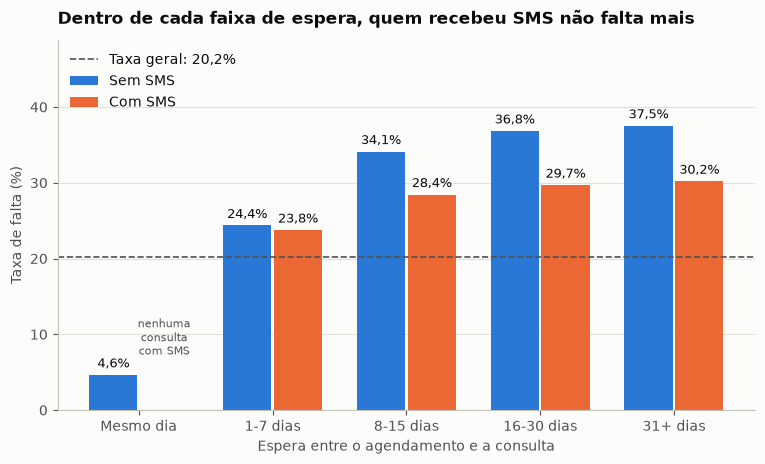

In [7]:
# 2a) Quantas consultas de cada faixa receberam SMS
sms_por_faixa = df.groupby("faixa_espera", observed=False)["recebeu_sms"].agg(consultas="size", com_sms="sum")
sms_por_faixa["pct_com_sms"] = sms_por_faixa["com_sms"] / sms_por_faixa["consultas"] * 100
print("Consultas que receberam SMS, por faixa de espera")
for faixa, linha in sms_por_faixa.iterrows():
    print(f"{faixa:<14}{fmt_num(linha['consultas']):>9} consultas{fmt_num(linha['com_sms']):>9} com SMS"
          f"{fmt_pct(linha['pct_com_sms']):>9}")

# Se este assert falhar, a leitura da seção precisa mudar
assert sms_por_faixa.loc["Mesmo dia", "com_sms"] == 0, "alguma consulta do mesmo dia recebeu SMS"
assert sms_por_faixa["consultas"].sum() == len(df)
print("\nOK: nenhuma consulta do mesmo dia recebeu SMS.")

# A partir de quantos dias de espera aparece SMS?
primeiro_dia_sms = int(df.loc[df["recebeu_sms"] == 1, "dias_espera"].min())
sem_chance_de_sms = df["dias_espera"] < primeiro_dia_sms
assert df.loc[sem_chance_de_sms, "recebeu_sms"].sum() == 0
print(f"Menor espera com SMS: {primeiro_dia_sms} dias.")
print(f"Consultas com menos de {primeiro_dia_sms} dias de espera (0, 1 e 2 dias): {fmt_num(sem_chance_de_sms.sum())}, "
      f"das quais {fmt_num(df.loc[sem_chance_de_sms, 'recebeu_sms'].sum())} com SMS.")

# 2b) Taxa com e sem SMS dentro de cada faixa
por_faixa_sms = df.groupby(["faixa_espera", "recebeu_sms"], observed=True)["faltou"].agg(
    consultas="size", faltas="sum")
por_faixa_sms["taxa_pct"] = por_faixa_sms["faltas"] / por_faixa_sms["consultas"] * 100
taxa_sms_faixa = por_faixa_sms["taxa_pct"].unstack("recebeu_sms").reindex(ORDEM_FAIXA_ESPERA)

print("\nTaxa de falta dentro de cada faixa de espera")
for faixa, linha in taxa_sms_faixa.iterrows():
    com = "sem consultas com SMS" if pd.isna(linha[1]) else fmt_pct(linha[1])
    print(f"{faixa:<14} sem SMS: {fmt_pct(linha[0]):>6}   com SMS: {com}")

print("\nDiferença (sem SMS menos com SMS), em pontos percentuais")
for faixa in ORDEM_FAIXA_ESPERA[1:]:
    dif = taxa_sms_faixa.loc[faixa, 0] - taxa_sms_faixa.loc[faixa, 1]
    print(f"{faixa:<14}{dif:.1f}".replace(".", ","))

# Só as consultas com antecedência (tira o mesmo dia da comparação crua)
antecedencia = taxa_por(com_rotulo_sms(df[df["faixa_espera"] != "Mesmo dia"]), "sms")
print("\nComparação crua só com as consultas com antecedência (sem o mesmo dia)")
imprimir_taxas(antecedencia, "sms")

# Gráfico agrupado: duas barras por faixa
x = np.arange(len(ORDEM_FAIXA_ESPERA))
largura = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
barras_sem = ax.bar(x - largura / 2 - 0.01, taxa_sms_faixa[0], width=largura, color=AZUL, label="Sem SMS")
barras_com = ax.bar(x + largura / 2 + 0.01, taxa_sms_faixa[1].fillna(0), width=largura, color=LARANJA, label="Com SMS")
teto = taxa_sms_faixa.max().max() * 1.3
for i, faixa in enumerate(ORDEM_FAIXA_ESPERA):
    ax.text(x[i] - largura / 2 - 0.01, taxa_sms_faixa.loc[faixa, 0] + teto * 0.012, fmt_pct(taxa_sms_faixa.loc[faixa, 0]),
            ha="center", va="bottom", color=TEXTO, fontsize=9)
    if pd.isna(taxa_sms_faixa.loc[faixa, 1]):
        ax.text(x[i] + largura / 2 + 0.01, teto * 0.14, "nenhuma\nconsulta\ncom SMS", ha="center", va="bottom",
                color=TEXTO_2, fontsize=8)
    else:
        ax.text(x[i] + largura / 2 + 0.01, taxa_sms_faixa.loc[faixa, 1] + teto * 0.012, fmt_pct(taxa_sms_faixa.loc[faixa, 1]),
                ha="center", va="bottom", color=TEXTO, fontsize=9)
ax.axhline(TAXA_GERAL, color=TEXTO_2, linestyle="--", linewidth=1.2, label=f"Taxa geral: {fmt_pct(TAXA_GERAL)}")
ax.set_xticks(x, ORDEM_FAIXA_ESPERA)
ax.set_ylim(0, teto)
ax.set_ylabel("Taxa de falta (%)")
ax.set_xlabel("Espera entre o agendamento e a consulta")
ax.yaxis.grid(True, color=GRADE, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper left")
ax.set_title("Dentro de cada faixa de espera, quem recebeu SMS não falta mais", loc="left")
plt.show()

**Leitura do passo 2.** O SMS só aparece a partir de **3 dias de espera**: as **50.500** consultas com 0, 1 ou 2 dias de
espera (38.562 do mesmo dia) não tiveram nenhum SMS. Nas faixas com SMS, ele chegou a 35,9% das consultas de 1 a 7 dias
(já contando os 3 a 7), 58,6% das de 8 a 15, 60,5% das de 16 a 30 e 61,8% das de 31 dias ou mais. Por isso o grupo "sem
SMS" está cheio de consultas do mesmo dia, que quase não faltam (4,6%), e isso puxa a taxa dele para baixo. A comparação
crua misturava dois efeitos: o do SMS e o da espera.

Comparando **dentro de cada faixa**, o quadro muda. Sem SMS contra com SMS: 24,4% contra 23,8% (1 a 7 dias), 34,1%
contra 28,4% (8 a 15), 36,8% contra 29,7% (16 a 30) e 37,5% contra 30,2% (31 dias ou mais). Em todas as faixas a taxa
**com SMS é menor**. Em 1 a 7 dias a diferença é praticamente nula (0,6 ponto); de 8 dias em diante, quem recebeu SMS
falta de 5,7 a 7,3 pontos percentuais a menos (cerca de 6 a 7). Mesmo tirando só o mesmo dia da comparação crua, a
ordem se inverte: 29,4% sem SMS contra 27,6% com SMS. Esse é o caso clássico de **correlação espúria**: o SMS "parecia"
aumentar a falta porque andava junto com a espera, e a espera é o fator mais associado à falta.

**Cuidado com o outro lado:** isso **não prova** que o SMS reduz a falta. Quem recebe SMS não foi sorteado (pode ser,
por exemplo, quem deixou telefone no cadastro). O que os números permitem dizer é que, dentro das faixas, não há sinal
de que o SMS aumente a falta, e a taxa com SMS é menor em todas as faixas. Mas essa é uma **associação**: saber se o
SMS reduz a falta exigiria um teste controlado.

## Seção 4: Quem falta mais por idade?

**Pergunta:** algum grupo de idade falta mais que os outros? Usamos as faixas etárias da base tratada.

0-12             21.035 consultas    4.306 faltas    20,5%
13-17             6.343 consultas    1.690 faltas    26,6%
18-29            16.729 consultas    4.122 faltas    24,6%
30-44            22.021 consultas    4.805 faltas    21,8%
45-59            23.221 consultas    4.150 faltas    17,9%
60+              21.172 consultas    3.241 faltas    15,3%


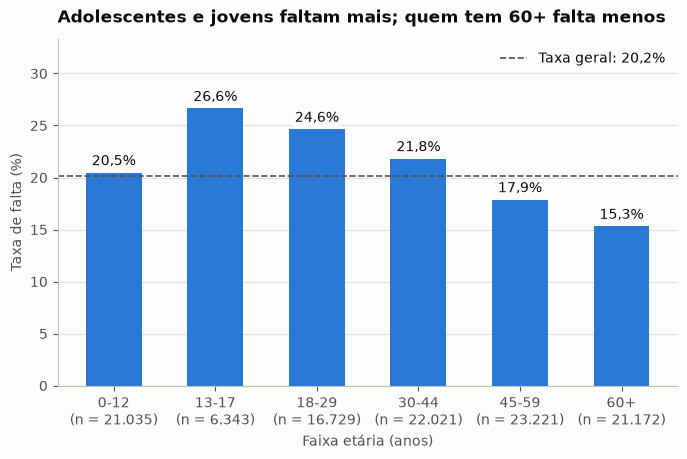

In [8]:
tab_idade = taxa_por(df, "faixa_etaria")
imprimir_taxas(tab_idade, "faixa_etaria")

assert tab_idade["consultas"].sum() == len(df)
assert list(tab_idade["faixa_etaria"]) == ORDEM_FAIXA_ETARIA

grafico_taxa(tab_idade, "faixa_etaria", "Adolescentes e jovens faltam mais; quem tem 60+ falta menos",
             mostrar_n=True, xlabel="Faixa etária (anos)")
plt.show()

**Leitura.** A falta tem uma forma de "montanha" por idade. O pico está nos **adolescentes de 13 a 17 anos**
(**26,6%**), seguidos dos jovens de 18 a 29 (**24,6%**), ambos acima da taxa geral de 20,2%. A partir daí a taxa cai:
21,8% entre 30 e 44, 17,9% entre 45 e 59 e **15,3%** em quem tem 60 anos ou mais, o grupo mais assíduo. As crianças de
0 a 12 anos ficam em 20,5%, perto da média (possivelmente porque quem decide por elas é o responsável). Esta é uma leitura por grupo, sem
cruzar com a espera: não sabemos ainda se os jovens faltam mais por serem jovens ou por marcarem com mais antecedência.

## Seção 5: Algum dia da semana falha mais?

**Pergunta:** existe um dia da semana em que a falta é maior? Mostramos também quantas consultas há em cada dia,
porque taxa calculada em cima de poucas consultas é pouco confiável.

Segunda          22.713 consultas    4.689 faltas    20,6%
Terça            25.638 consultas    5.150 faltas    20,1%
Quarta           25.866 consultas    5.092 faltas    19,7%
Quinta           17.246 consultas    3.337 faltas    19,3%
Sexta            19.019 consultas    4.037 faltas    21,2%
Sábado               39 consultas        9 faltas    23,1%

Sábado: 39 consultas e 9 faltas (amostra pequena).
De segunda a sexta, a taxa vai de 19,3% (Quinta) a 21,2% (Sexta).


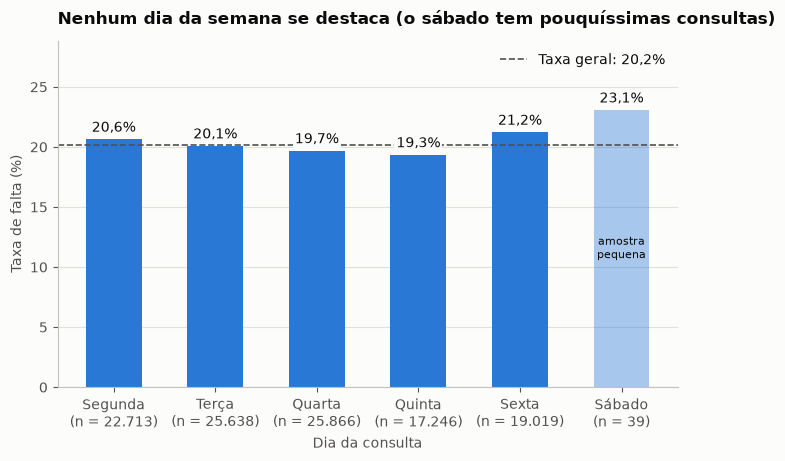

In [9]:
tab_dia = taxa_por(df, "dia_semana")
imprimir_taxas(tab_dia, "dia_semana")

assert list(tab_dia["dia_semana"]) == ORDEM_DIA_SEMANA, "a tabela de dias não tem os 6 rótulos do contrato"
assert tab_dia["consultas"].sum() == len(df)

sabado = tab_dia.loc[tab_dia["dia_semana"] == "Sábado"].iloc[0]
print(f"\nSábado: {fmt_num(sabado['consultas'])} consultas e {fmt_num(sabado['faltas'])} faltas (amostra pequena).")
dias_uteis = tab_dia[tab_dia["dia_semana"] != "Sábado"]
print(f"De segunda a sexta, a taxa vai de {fmt_pct(dias_uteis['taxa_pct'].min())} "
      f"({dias_uteis.loc[dias_uteis['taxa_pct'].idxmin(), 'dia_semana']}) a {fmt_pct(dias_uteis['taxa_pct'].max())} "
      f"({dias_uteis.loc[dias_uteis['taxa_pct'].idxmax(), 'dia_semana']}).")

ax = grafico_taxa(tab_dia, "dia_semana", "Nenhum dia da semana se destaca (o sábado tem pouquíssimas consultas)",
                  mostrar_n=True, xlabel="Dia da consulta")
barra_sabado = ax.patches[-1]
barra_sabado.set_alpha(0.4)  # barra mais clara: amostra pequena
ax.text(5, sabado["taxa_pct"] / 2, "amostra\npequena", ha="center", va="center", color=TEXTO, fontsize=8)
plt.show()

**Leitura.** De segunda a sexta a taxa é muito parecida: vai de **19,3%** (quinta) a **21,2%** (sexta), tudo perto
da taxa geral de 20,2%. Não há um dia que justifique, sozinho, uma ação diferente. O **sábado** aparece com **23,1%**,
mas são só **39 consultas** (9 faltas): com tão poucos casos, uma falta a mais ou a menos muda muito a taxa, então
**não tiramos conclusão** sobre o sábado (a barra está mais clara de propósito).

## Seção 6: Quais bairros têm mais falta?

**Pergunta:** há bairros onde a falta é maior? Para a taxa ser confiável, só entram os bairros com **pelo menos
500 consultas** (o "corte de 500"). Mostramos os 10 com maior taxa de falta.

Bairros na base: 81
Bairros com 500 consultas ou mais (entram no corte): 54, com 104.100 consultas (94,2% do total)
Bairros fora do corte: 27, com 6.421 consultas

Maiores taxas entre os bairros FORA do corte (por que o corte existe):
ILHAS OCEÂNICAS DE TRINDADE        2 consultas        2 faltas   100,0%
SANTA CECÍLIA       448 consultas      123 faltas    27,5%
HORTO               175 consultas       42 faltas    24,0%

Top 10 bairros por taxa de falta (entre os que têm 500 consultas ou mais):
SANTOS DUMONT     1.276 consultas      369 faltas    28,9%
SANTA CLARA         506 consultas      134 faltas    26,5%
ITARARÉ           3.514 consultas      923 faltas    26,3%
JESUS DE NAZARETH    2.853 consultas      696 faltas    24,4%
ILHA DO PRÍNCIPE    2.266 consultas      532 faltas    23,5%
CARATOÍRA         2.565 consultas      591 faltas    23,0%
ANDORINHAS        2.262 consultas      521 faltas    23,0%
PRAIA DO SUÁ      1.288 consultas      294 faltas    22,8%
GURIGICA          2.01

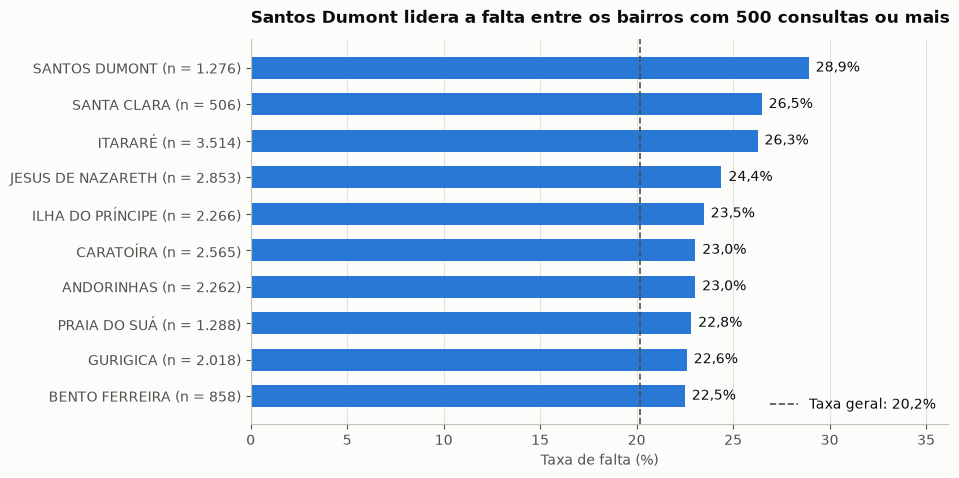

In [10]:
tab_bairro = taxa_por(df, "bairro")
elegiveis = tab_bairro[tab_bairro["consultas"] >= 500]
fora_do_corte = tab_bairro[tab_bairro["consultas"] < 500]

print(f"Bairros na base: {len(tab_bairro)}")
print(f"Bairros com 500 consultas ou mais (entram no corte): {len(elegiveis)}, "
      f"com {fmt_num(elegiveis['consultas'].sum())} consultas "
      f"({fmt_pct(elegiveis['consultas'].sum() / len(df) * 100)} do total)")
print(f"Bairros fora do corte: {len(fora_do_corte)}, com {fmt_num(fora_do_corte['consultas'].sum())} consultas")
print("\nMaiores taxas entre os bairros FORA do corte (por que o corte existe):")
imprimir_taxas(fora_do_corte.sort_values("taxa_pct", ascending=False).head(3), "bairro")

top10 = elegiveis.sort_values("taxa_pct", ascending=False).head(10)
assert (top10["consultas"] >= 500).all(), "um bairro do top 10 tem menos de 500 consultas"
assert top10["taxa_pct"].is_monotonic_decreasing, "o top 10 não está em ordem decrescente de taxa"
assert len(top10) == 10

print("\nTop 10 bairros por taxa de falta (entre os que têm 500 consultas ou mais):")
imprimir_taxas(top10, "bairro")
menor = elegiveis.loc[elegiveis["taxa_pct"].idxmin()]
print(f"\nMenor taxa entre os bairros do corte: {menor['bairro']} ({fmt_pct(menor['taxa_pct'])}, "
      f"{fmt_num(menor['consultas'])} consultas)")

fig, ax = plt.subplots(figsize=(9, 5))
grafico_taxa(top10, "bairro", "Santos Dumont lidera a falta entre os bairros com 500 consultas ou mais",
             ax=ax, horizontal=True, mostrar_n=True)
plt.show()

**Leitura.** Dos 81 bairros da base, **54** têm 500 consultas ou mais e entram na comparação: juntos reúnem
**104.100 consultas (94,2%** do total). O corte existe porque, com poucas consultas, a taxa é puro acaso: o bairro
**ILHAS OCEÂNICAS DE TRINDADE** tem 100% de falta, mas são apenas 2 consultas. Entre os que entram, o maior é
**SANTOS DUMONT** (**28,9%**, 1.276 consultas), seguido de SANTA CLARA (26,5%, 506 consultas) e ITARARÉ (26,3%,
3.514 consultas); a menor taxa do corte é a de DO CABRAL (15,7%). Todo corte é uma regra arbitrária: SANTA CECÍLIA, com
448 consultas e 27,5%, ficou logo abaixo dele e por isso não aparece no gráfico. Mantemos o destaque de SANTOS DUMONT, mas as posições 4 a 10
(de 24,4% a 22,5%) ficam a cerca de 2 pontos umas das outras, então a ordem entre elas não é confiável. A diferença
entre o topo e a média é real nos números, mas o
bairro **não explica a falta sozinho**: não controlamos espera nem idade por bairro, então o ranking serve como
**pista** para olhar no dashboard, não como conclusão.

## Seção 7: Como as variáveis numéricas se correlacionam com a falta?

**Pergunta:** olhando todas as variáveis numéricas de uma vez, alguma tem relação forte com a falta? Calculamos a
correlação (de Pearson, entre -1 e +1) de `faltou` com `idade`, `dias_espera`, `recebeu_sms`, `bolsa_familia`,
`hipertensao`, `diabetes`, `alcoolismo` e `tem_deficiencia`. Perto de 0 quer dizer "quase nenhuma relação linear".
Vermelho = anda junto com a falta; azul = anda ao contrário.

Correlação de cada variável com `faltou` (da mais forte para a mais fraca):
  dias de espera    0,19
  recebeu SMS       0,13
  idade            -0,06
  hipertensão      -0,04
  Bolsa Família     0,03
  diabetes         -0,02
  tem deficiência  -0,01
  alcoolismo        0,00

Correlação entre dias de espera e recebeu SMS: 0,40
Maior correlação com a falta (em valor absoluto): 0,19
Alcoolismo e deficiência: |r| máximo = 0,008


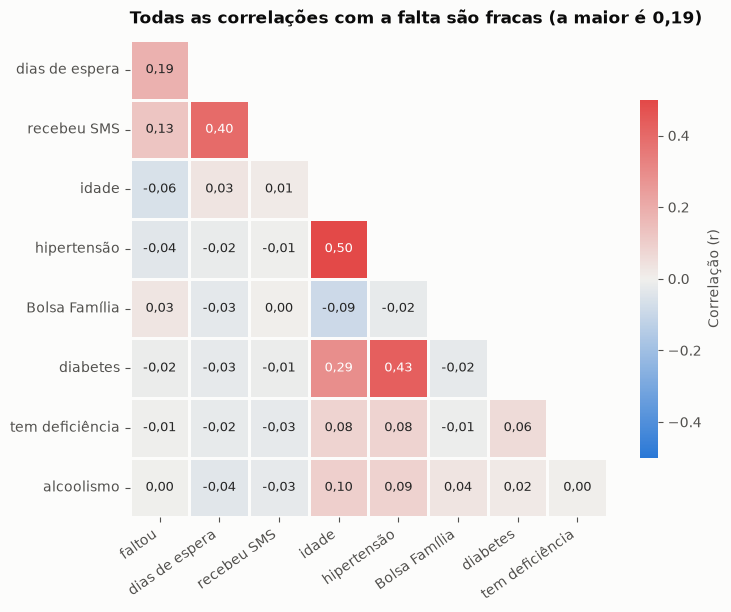

In [11]:
colunas_corr = ["faltou", "idade", "dias_espera", "recebeu_sms", "bolsa_familia",
                "hipertensao", "diabetes", "alcoolismo", "tem_deficiencia"]
nomes = {"faltou": "faltou", "idade": "idade", "dias_espera": "dias de espera", "recebeu_sms": "recebeu SMS",
         "bolsa_familia": "Bolsa Família", "hipertensao": "hipertensão", "diabetes": "diabetes",
         "alcoolismo": "alcoolismo", "tem_deficiencia": "tem deficiência"}

corr = df[colunas_corr].corr()
com_a_falta = corr["faltou"].drop("faltou")
# Variáveis ordenadas pela força da correlação com a falta (sem olhar o sinal)
ordem = ["faltou"] + com_a_falta.abs().sort_values(ascending=False).index.tolist()
corr = corr.loc[ordem, ordem]

print("Correlação de cada variável com `faltou` (da mais forte para a mais fraca):")
for variavel in ordem[1:]:
    print(f"  {nomes[variavel]:<16}{fmt_r(corr.loc[variavel, 'faltou']):>6}")
print(f"\nCorrelação entre dias de espera e recebeu SMS: {fmt_r(corr.loc['recebeu_sms', 'dias_espera'])}")
maior_corr = com_a_falta.abs().max()
print(f"Maior correlação com a falta (em valor absoluto): {fmt_r(maior_corr)}")
print(f"Alcoolismo e deficiência: |r| máximo = {max(abs(corr.loc['alcoolismo', 'faltou']), abs(corr.loc['tem_deficiencia', 'faltou'])):.3f}".replace(".", ","))

assert maior_corr < 0.3, "alguma correlação com a falta deixou de ser fraca: revisar a leitura"

# Heatmap só do triângulo inferior (a matriz é simétrica)
matriz = corr.iloc[1:, :-1]
mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)
anotacoes = matriz.map(fmt_r).to_numpy()
cores_div = LinearSegmentedColormap.from_list("azul_vermelho", [AZUL, NEUTRO, VERMELHO])

fig, ax = plt.subplots(figsize=(8.5, 6.2))
sns.heatmap(matriz, mask=mascara, annot=anotacoes, fmt="", cmap=cores_div, vmin=-0.5, vmax=0.5, center=0,
            linewidths=2, linecolor=SUPERFICIE, square=True,
            cbar_kws={"label": "Correlação (r)", "shrink": 0.75}, annot_kws={"fontsize": 9}, ax=ax)
ax.set_xticklabels([nomes[c] for c in matriz.columns], rotation=35, ha="right")
ax.set_yticklabels([nomes[c] for c in matriz.index], rotation=0)
ax.set_title(f"Todas as correlações com a falta são fracas (a maior é {fmt_r(maior_corr)})", loc="left")
plt.show()

**Leitura.** As correlações com a falta são **todas fracas**: a maior é a dos **dias de espera (0,19)**, seguida de
**recebeu SMS (0,13)**; depois vêm idade (-0,06), hipertensão (-0,04) e Bolsa Família (0,03), e alcoolismo e
deficiência ficam praticamente em zero (|r| menor que 0,01). Duas observações. Primeiro, correlação fraca não quer
dizer "sem efeito": nossas variáveis são quase todas 0/1, o que limita o valor da correlação, e, no caso da espera, a
relação **não é linear** (a taxa salta do mesmo dia para a antecedência e para de crescer a partir de 16 dias), o que
também deixa o r baixo. A análise por faixa das seções anteriores mostra diferenças grandes (por exemplo, 4,6% contra
28,5% na espera). Segundo, o heatmap mostra
o que a Seção 3 explicou: o SMS tem correlação positiva com a falta (0,13) e, ao mesmo tempo, correlação de **0,40** com os
dias de espera: a espera é a candidata a explicar a primeira. **Correlação não é causa**, e o SMS é o exemplo:
"andar junto" com a falta não significa provocar a falta.

## Seção 8: Achados e próximos passos

Antes dos achados, os números que eles citam, recalculados a partir das tabelas das seções anteriores:

In [12]:
print(f"Taxa geral: {fmt_pct(TAXA_GERAL)}")
print(f"Mesmo dia: {fmt_pct(taxa_mesmo_dia)} | com antecedência: {fmt_pct(taxa_antecedencia)}")
print(f"Espera de 16 a 30 dias: {fmt_pct(taxa_de(tab_espera, 'faixa_espera', '16-30 dias'))} | "
      f"31 dias ou mais: {fmt_pct(taxa_de(tab_espera, 'faixa_espera', '31+ dias'))}")
print(f"SMS cru: com SMS {fmt_pct(taxa_com_sms)} | sem SMS {fmt_pct(taxa_sem_sms)}")
print(f"SMS dentro de 8 a 15 dias: sem {fmt_pct(taxa_sms_faixa.loc['8-15 dias', 0])} | com {fmt_pct(taxa_sms_faixa.loc['8-15 dias', 1])}")
print(f"SMS dentro de 31 dias ou mais: sem {fmt_pct(taxa_sms_faixa.loc['31+ dias', 0])} | com {fmt_pct(taxa_sms_faixa.loc['31+ dias', 1])}")
print(f"Idade 13-17: {fmt_pct(taxa_de(tab_idade, 'faixa_etaria', '13-17'))} | 18-29: {fmt_pct(taxa_de(tab_idade, 'faixa_etaria', '18-29'))} | 60+: {fmt_pct(taxa_de(tab_idade, 'faixa_etaria', '60+'))}")
print(f"Dias de segunda a sexta: de {fmt_pct(dias_uteis['taxa_pct'].min())} a {fmt_pct(dias_uteis['taxa_pct'].max())}")
print(f"Bairro com maior taxa (500+ consultas): {top10.iloc[0]['bairro']}, {fmt_pct(top10.iloc[0]['taxa_pct'])}")
print(f"Maior correlação com a falta: dias de espera, {fmt_r(corr.loc['dias_espera', 'faltou'])}")

assert top10.iloc[0]["bairro"] == "SANTOS DUMONT"
assert corr["faltou"].drop("faltou").abs().idxmax() == "dias_espera"

Taxa geral: 20,2%
Mesmo dia: 4,6% | com antecedência: 28,5%
Espera de 16 a 30 dias: 32,5% | 31 dias ou mais: 33,0%
SMS cru: com SMS 27,6% | sem SMS 16,7%
SMS dentro de 8 a 15 dias: sem 34,1% | com 28,4%
SMS dentro de 31 dias ou mais: sem 37,5% | com 30,2%
Idade 13-17: 26,6% | 18-29: 24,6% | 60+: 15,3%
Dias de segunda a sexta: de 19,3% a 21,2%
Bairro com maior taxa (500+ consultas): SANTOS DUMONT, 28,9%
Maior correlação com a falta: dias de espera, 0,19


### Achados

1. **A espera é o fator mais associado à falta.** Quem marca para o mesmo dia falta em **4,6%** das consultas; quem marca com
   antecedência, em **28,5%**. A partir de 16 dias a taxa passa de **32%** (32,5% e 33,0%) e praticamente para de
   crescer. Os dias de espera também têm a maior correlação com a falta (0,19), ainda que fraca.
2. **O SMS não "causa" mais falta: era correlação espúria.** Cru, o SMS parece aumentar a falta (**27,6%** com SMS
   contra **16,7%** sem). Mas nenhuma consulta do mesmo dia recebeu SMS, e dentro de cada faixa de espera a taxa
   com SMS é menor: em 1 a 7 dias a diferença é praticamente nula (24,4% contra 23,8%), e de 8 dias em diante quem recebeu
   SMS falta cerca de 6 a 7 pontos a menos (por exemplo, 28,4% contra 34,1% em 8 a 15 dias, e 30,2% contra 37,5% em 31
   dias ou mais). Isso é uma **associação**, não prova que o SMS reduz a falta; mostra que a comparação crua estava
   contaminada pela espera.
3. **Adolescentes e jovens faltam mais; quem tem 60+ falta menos.** 13 a 17 anos: **26,6%**; 18 a 29: **24,6%**;
   60 anos ou mais: **15,3%** (taxa geral: 20,2%).
4. **O dia da semana quase não importa.** De segunda a sexta a taxa fica entre **19,3%** e **21,2%**. O sábado (39
   consultas) é amostra pequena demais para concluir.
5. **Alguns bairros se destacam, com cautela.** Entre os 54 bairros com 500 consultas ou mais, **SANTOS DUMONT** tem a
   maior taxa (**28,9%**). É uma pista para o dashboard, não uma conclusão.

### Limites desta primeira versão

A análise é descritiva: olha um fator de cada vez, sem controlar vários ao mesmo tempo, e a base não traz o horário
da consulta (só a data). Por isso os resultados acima são **hipóteses bem fundamentadas nos dados**, não provas de
causa.

### Próximos passos

O que veio depois deste notebook:

- **Notebook 03** (`03_grupo_de_risco`): cruzou a espera com a idade e mediu o grupo de maior risco (13 a 29 anos e
  espera de 16 dias ou mais): 5.422 consultas, 4,9% da agenda, falta em 40,2% (o dobro da taxa geral) e concentra 9,8%
  das faltas.
- **Dashboard** em página web (Next.js/React), publicado no GitHub Pages, sobre a mesma base tratada
  (`consultas_tratadas.csv`), com a taxa de falta e filtros por **idade, dia da semana, bairro e dias de espera**, nas
  mesmas faixas e definições deste notebook. Os números são calculados em Python e a página só os mostra:
  https://cauedev30.github.io/analise-no-show-consultas/
- **Recomendação:** um **agente de disparo de lembretes** (Classifica, Dispara e Libera), com mais de um lembrete para
  o grupo de maior risco. Ele começa em teste, porque a análise é descritiva. Na base, o disparo registrado é o SMS
  (coluna `recebeu_sms`), por isso este notebook fala em SMS. O overbooking, que a proposta citava como exemplo, saiu:
  ficou uma solução só. A troca está registrada em `docs/processo.md`.